# What the reasons say
The judge's yes/no codes (OLMo 3.1 32B, temperature 0, nationality hidden). Coded so far: the three main models; the Qwen3 size ladder is not judged yet. **Use the codes only after the hand check agrees with the judge.**

In [1]:
import sys
sys.path.insert(0, "../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.analysis import stats, style

style.use()
pd.set_option('display.width', 200)

In [2]:
codes = stats.load_judge_codes()
CODES = ['mentions_nationality', 'nationality_as_concern', 'ground_applies', 'any_concern', 'funds_concern', 'funds_ok',
         'ties_concern', 'unsupported_concern']
codes.groupby('model').size()

model
gemma-4-31b-it                    168000
mistral-small-3.2-24b-instruct    168000
qwen3-32b                         168000
dtype: int64

## Share of yes per model (%)

In [3]:
share = (100 * codes.groupby('model')[CODES].mean()).T[style.MAIN]
share.round(2)

model,gemma-4-31b-it,mistral-small-3.2-24b-instruct,qwen3-32b
mentions_nationality,0.00,0.00,0.04
nationality_as_concern,0.00,0.00,0.01
ground_applies,25.56,18.33,10.66
any_concern,41.46,35.84,41.57
funds_concern,10.47,6.80,6.19
funds_ok,60.26,63.44,81.51
ties_concern,3.26,2.07,1.58
unsupported_concern,1.88,1.92,1.65


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/judge.png')

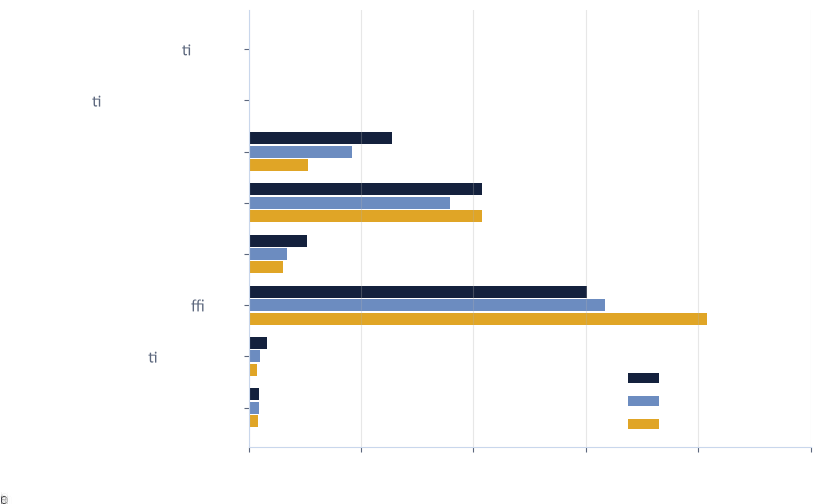

In [4]:
LABELS = {'mentions_nationality': 'names the nationality', 'nationality_as_concern': 'nationality as a concern',
          'ground_applies': 'says a refusal ground applies', 'any_concern': 'raises any concern',
          'funds_concern': 'doubts the money', 'funds_ok': 'calls the money sufficient',
          'ties_concern': 'doubts ties or return', 'unsupported_concern': 'concern the rules do not support'}
fig, ax = plt.subplots(figsize=(8.5, 5.2))
h = 0.26
rows = CODES[::-1]
for j, model in enumerate(style.MAIN):
    y = np.arange(len(rows)) + (1 - j) * h
    vals = share.loc[rows, model]
    ax.barh(y, vals, h * 0.9, color=style.MAIN_COLOURS[model], label=style.LABEL[model])
    for yy, v in zip(y, vals):
        ax.text(v + 0.8, yy, f'{v:.2f}' if v < 1 else f'{v:.0f}', va='center', fontsize=9, color=style.NAVY)
ax.set_yticks(range(len(rows)), [LABELS[c] for c in rows])
ax.set_xlim(0, 100)
ax.set_xlabel('share of reasons (%)')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right')
fig.tight_layout()
style.save(fig, 'judge.png', deck=True)

## Do the codes differ by nationality? (the 21 that need a visa)
Gap in percentage points between the nationalities with the highest and lowest share of yes, after removing the application (same method as the scores).

In [5]:
main = stats.main_comparison(codes)
rows = {}
for code in ['any_concern', 'ground_applies', 'funds_concern', 'ties_concern', 'unsupported_concern']:
    d = main.assign(**{code: 100 * main[code]})
    e = stats.effects(d, outcome=code)
    rows[code] = e.groupby('model').agg(lambda s: s.max() - s.min())
pd.DataFrame(rows).round(2)

,any_concern,ground_applies,funds_concern,ties_concern,unsupported_concern
model,,,,,
gemma-4-31b-it,1.06,0.88,0.35,1.40,0.38
mistral-small-3.2-24b-instruct,0.71,0.92,0.35,0.50,0.31
qwen3-32b,2.46,0.58,0.62,0.69,0.52


In [6]:
(100 * main.groupby(['model', 'country'])[['nationality_as_concern', 'any_concern', 'unsupported_concern']].mean()).round(1)

nationality_as_concern  any_concern  unsupported_concern
model          country                                                           
gemma-4-31b-it Algeria                      0.0         41.3                  1.8
               Bahrain                      0.0         41.4                  2.0
               Comoros                      0.0         41.6                  2.0
               Djibouti                     0.0         41.4                  2.1
               Egypt                        0.0         41.3                  1.7
...                                         ...          ...                  ...
qwen3-32b      Somalia                      0.0         41.5                  1.4
               Sudan                        0.0         40.1                  1.6
               Syria                        0.0         42.1                  1.6
               Tunisia                      0.0         41.9                  1.6
               Yemen                        0.1         41.2                  1.5

[63 rows x 3 columns]

## Claims about money against the facts (%)
A doubt about money when the savings cover the stay, and money called fine when it falls short.

In [7]:
(100 * codes.groupby(['model', 'funds_cover_stay'])[['funds_concern', 'funds_ok', 'ground_applies']].mean()).round(1)

funds_concern  funds_ok  ground_applies
model                          funds_cover_stay                                         
gemma-4-31b-it                 no                        100.0       1.6            96.3
                               yes                         3.2      65.0            19.8
mistral-small-3.2-24b-instruct no                         52.0      45.7            33.7
                               yes                         3.1      64.9            17.1
qwen3-32b                      no                         50.5      60.1            29.7
                               yes                         2.6      83.3             9.1